# <span style="color:darkblue"> Lecture 19: Text Analysis </span>

<font size = "5">

Intro text analysis

https://www.youtube.com/watch?v=IRKDrrzh4dE

# <span style="color:darkblue"> I. Setup Working Environment </span>

In [1]:

# Import SK-Learn library for machine learning functions
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS 
from sklearn.decomposition import TruncatedSVD
from sklearn.model_selection import train_test_split



# Import standard data analysis packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import Kmenas
from sklearn.cluster import MiniBatchKMeans

import faiss


# <span style="color:darkblue"> II. Data </span>

<font size = "5">

We will analyze a dataset on Amazon Reviews

https://www.kaggle.com/datasets/yasserh/amazon-product-reviews-dataset/data


In [2]:
data = pd.read_csv("data_raw/amazon_reviews.csv")

len(data)


1597

<font size = "5">

Check features

In [3]:
data.columns

Index(['id', 'asins', 'brand', 'categories', 'colors', 'dateAdded',
       'dateUpdated', 'dimension', 'ean', 'keys', 'manufacturer',
       'manufacturerNumber', 'name', 'prices', 'reviews.date',
       'reviews.doRecommend', 'reviews.numHelpful', 'reviews.rating',
       'reviews.sourceURLs', 'reviews.text', 'reviews.title',
       'reviews.userCity', 'reviews.userProvince', 'reviews.username', 'sizes',
       'upc', 'weight'],
      dtype='object')

<font size = "5">

Check text

In [4]:
reviews = data["reviews.text"]

<font size = "5">

Check rating

(array([ 42.,   0.,  34.,   0.,   0., 124.,   0., 236.,   0., 741.]),
 array([1. , 1.4, 1.8, 2.2, 2.6, 3. , 3.4, 3.8, 4.2, 4.6, 5. ]),
 <BarContainer object of 10 artists>)

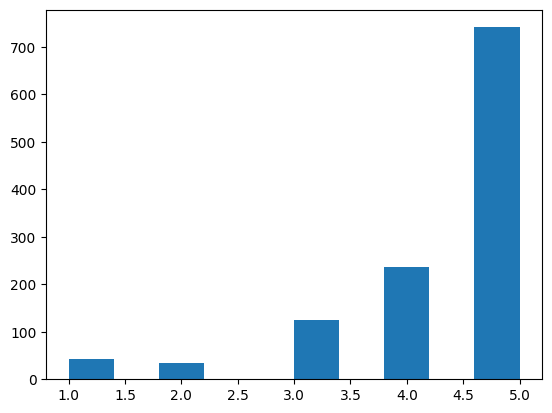

In [5]:
plt.hist(x = data["reviews.rating"])


<font size = "5">

Filter non-missing ratings data

- 26% missing data!
- Could generate selection bias in reviews

In [6]:
# Check for missing values
# A lot of reviews are missing review data
missing_values = data["reviews.rating"].isnull().sum()
percent_missing = missing_values /len(data)
print(percent_missing)

# Extract non-missing data
data_nonmissing = data[data["reviews.rating"].notnull()]

0.2629931120851597


# <span style="color:darkblue"> III. Bag of Words </span>


<font size = "5">

Stop words

- Commonly used words
- Available for different languages



In [7]:
# First ten English stop words
list(ENGLISH_STOP_WORDS)[0:10]

['found',
 'whereby',
 'yours',
 'towards',
 'thus',
 'forty',
 'below',
 'too',
 'per',
 'show']

<font size = "5">

Create custom stop words

In [8]:
# Here we added Python to the list of stop words
custom_stop_words = list(ENGLISH_STOP_WORDS) + ["Python"]

# You can also create your own list
# custom_stop_words = ["and","or","how"]


<font size = "5">

Count vectorizer

- Check for distinct words across all reviews
- Remove any stop words
- ```min_df``` is used to filter out words depending <br>
on how often they occur. For example, ```min_df=3``` <br>
only keeps words if they are mentioned at least 3 times

In [9]:
word_model = CountVectorizer(min_df=1,
                       stop_words=custom_stop_words)
word_model.fit(reviews)

C:\Users\adamk\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\feature_extraction\text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['python'] not in stop_words.
  warnings.warn(


CountVectorizer(stop_words=['found', 'whereby', 'yours', 'towards', 'thus',
                            'forty', 'below', 'too', 'per', 'show', 'less',
                            'latterly', 'myself', 'please', 'top', 'back',
                            'our', 'then', 'those', 'each', 'un', 'becomes',
                            'first', 'on', 'yourselves', 'nobody', 'amoungst',
                            'whereafter', 'give', 'several', ...])

<font size = "5">

Check Vocabulary

- Check in VS-Code Data Viewer
- You can use preliminary findings to decide whether <br>
to add more stop words

In [10]:
# Extract words in vocabulary and frequency
vocabulary = word_model.vocabulary_

# Convert to dataframew
frequency_words  = pd.DataFrame(vocabulary.items(),
                                columns=['Word', 'Frequency'])
                                
# Display sorted dataset                                
frequency_words.sort_values(by = "Frequency",ascending=False)

,Word,Frequency
4309,zumi,6194
4474,zooming,6193
4856,zoom,6192
5496,zombies,6191
2692,zippy,6190
...,...,...
1449,07,4
3398,04,3
484,000s,2
494,000,1


<font size = "5">

Create a dataset counting which words are used <br>
per review

- Each row is a different review
- Each column is a ${0,1}$ indicator on whether that <br>
word was mentioned
- Huge matrix!!

In [11]:
# Create X matrix
X = word_model.transform(reviews)

# Check dimension of X matrix
np.shape(X)

X_dataframe = pd.DataFrame(X)

<font size = "5">

Try it yourself!

Create a bag of words for the column "review.title".

- What are the most common words?



In [19]:
# Analyze the words in review titles
review_titles = data["reviews.title"].dropna()

title_word_model = CountVectorizer(
    min_df=1,
    stop_words=custom_stop_words
)
title_word_matrix = title_word_model.fit_transform(review_titles)

# Count word occurrences across all titles
word_counts = np.asarray(title_word_matrix.sum(axis=0)).flatten()
title_frequency = pd.DataFrame({
    "Word": title_word_model.get_feature_names_out(),
    "Count": word_counts
}).sort_values("Count", ascending=False)

title_frequency.head(20)



C:\Users\adamk\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\feature_extraction\text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['python'] not in stop_words.
  warnings.warn(


,Word,Count
740,helpful,845
1055,review,499
1289,yes,425
954,people,404
723,great,365
400,amazon,145
738,headphones,133
716,good,105
423,awesome,93
1235,use,88


# <span style="color:darkblue"> IV. Sentiment Analysis </span>

<font size = "5">
Sentiment analsys uses words to predict user ratings. <br>


- In this case we have ratings labels
- We'll use the data with nonmissing labels


In [13]:
# Write your own code

text = data_nonmissing["reviews.text"]
y    = data_nonmissing["reviews.rating"]

text_train, text_test, y_train, y_test = train_test_split(text, y,
                                                    random_state=0)

<font size = "5">

Extract vectorized X

In [14]:
# Create X matrix
word_model_train = CountVectorizer(min_df=1,
                       stop_words=custom_stop_words)
word_model_train.fit(text_train)
X_train = word_model_train.transform(text_train)

# Check dimension of X matrix
np.shape(X)

C:\Users\adamk\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\feature_extraction\text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['python'] not in stop_words.
  warnings.warn(


(1597, 6195)

<font size = "5">

We can compress the data using <br>
truncated singular value decomposition (SVD)

- This is an alternative to PCA that is better suited <br>
for sparse, binary data like text

In [15]:
svd = TruncatedSVD(n_components=3,random_state=42);
svd.fit(X_train)
X_svd_train = svd.transform(X_train)
np.shape(X_svd_train)

(882, 3)

[Text(0.5, 0, 'First Principal Component'),
 Text(0, 0.5, 'Rating of the Product')]

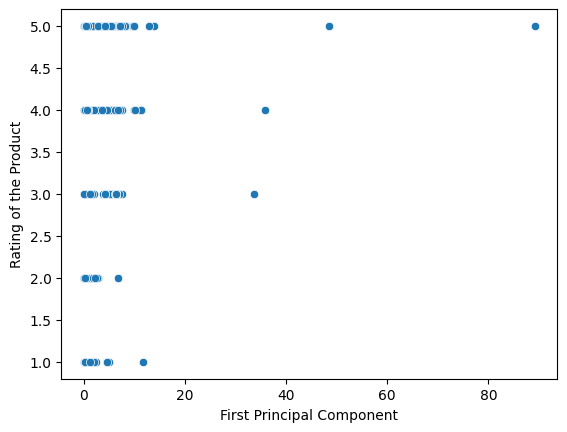

In [16]:
# Hue is used to color
ax = sns.scatterplot(x = X_svd_train[:,0],
                     y = y_train)
ax.set(xlabel='First Principal Component',
       ylabel='Rating of the Product')


<font size = "5">

Try it yourself!

Create a machine learning pipeline

- Run a support vector machine regression to predict user ratings
- What is the out-of-sample performance on the test data?
- Use your data to predict reviews that were missing
- How does the distribution of missing to non-missing reviews compare?



Test R²:   0.241
Test MAE:  0.541
Test RMSE: 0.883


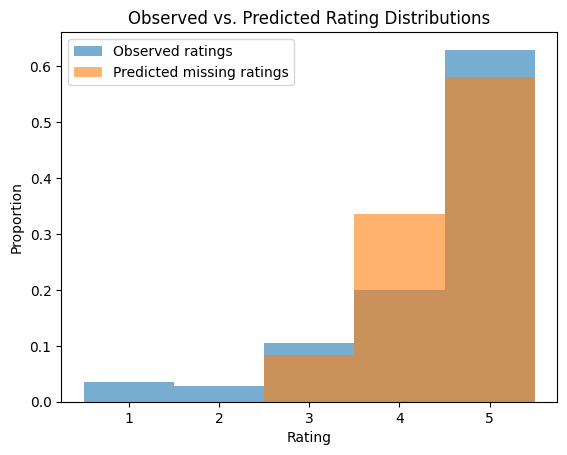

Observed mean rating: 4.36
Predicted mean for missing ratings: 4.49


In [20]:
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Fit the regression model and evaluate on held-out reviews
svr_model = SVR()
svr_model.fit(X_train, y_train)

X_test = word_model_train.transform(text_test.fillna("").astype(str))
y_pred_test = svr_model.predict(X_test)

print(f"Test R²:   {r2_score(y_test, y_pred_test):.3f}")
print(f"Test MAE:  {mean_absolute_error(y_test, y_pred_test):.3f}")
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_test)):.3f}")

# Predict ratings for reviews whose ratings are missing
missing_mask = data["reviews.rating"].isna()
missing_text = data.loc[missing_mask, "reviews.text"].fillna("").astype(str)
X_missing = word_model_train.transform(missing_text)
predicted_missing = np.clip(svr_model.predict(X_missing), 1, 5)

# Compare observed and predicted rating distributions
observed_ratings = data_nonmissing["reviews.rating"]

plt.hist(observed_ratings, bins=np.arange(0.5, 6, 1),
         density=True, alpha=0.6, label="Observed ratings")
plt.hist(predicted_missing, bins=np.arange(0.5, 6, 1),
         density=True, alpha=0.6, label="Predicted missing ratings")
plt.xlabel("Rating")
plt.ylabel("Proportion")
plt.title("Observed vs. Predicted Rating Distributions")
plt.legend()
plt.show()

print(f"Observed mean rating: {observed_ratings.mean():.2f}")
print(f"Predicted mean for missing ratings: {predicted_missing.mean():.2f}")

<font size = "5">

Try it yourself!

- What happens if you change the minimum frequency of words <br>
and/or change the number of components?

C:\Users\adamk\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\feature_extraction\text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['python'] not in stop_words.
  warnings.warn(
C:\Users\adamk\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\feature_extraction\text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['python'] not in stop_words.
  warnings.warn(
C:\Users\adamk\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\feature_extraction\text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['python'] not in 

    min_df  n_components  vocabulary_size        R2       MAE
15      10            50              912  0.111670  0.556883
11       5            50             1533  0.107422  0.556147
7        2            50             2807  0.104143  0.556679
3        1            50             4792  0.099492  0.557083
10       5            25             1533 -0.001830  0.588263
14      10            25              912 -0.002552  0.593079
6        2            25             2807 -0.004900  0.588460
2        1            25             4792 -0.008458  0.589816
5        2            10             2807 -0.140830  0.624213
1        1            10             4792 -0.141501  0.624408
9        5            10             1533 -0.141804  0.624592
13      10            10              912 -0.142597  0.624657
8        5             3             1533 -0.203458  0.646881
12      10             3              912 -0.203929  0.647153
4        2             3             2807 -0.204170  0.647102
0       

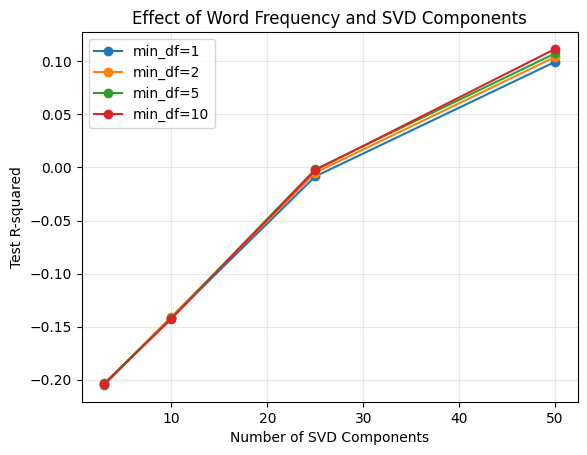

In [21]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error

# Compare minimum word frequency and the number of SVD components


results = []

for min_df in [1, 2, 5, 10]:
    for n_components in [3, 10, 25, 50]:
        model = Pipeline([
            ("count", CountVectorizer(
                min_df=min_df,
                stop_words=custom_stop_words
            )),
            ("svd", TruncatedSVD(
                n_components=n_components,
                random_state=42
            )),
            ("svr", SVR())
        ])

        model.fit(text_train, y_train)
        predictions = model.predict(text_test)

        results.append({
            "min_df": min_df,
            "n_components": n_components,
            "vocabulary_size": len(model.named_steps["count"].vocabulary_),
            "R2": r2_score(y_test, predictions),
            "MAE": mean_absolute_error(y_test, predictions)
        })

results_df = pd.DataFrame(results)
print(results_df.sort_values("R2", ascending=False))

# Plot test R-squared for each combination
for min_df in results_df["min_df"].unique():
    subset = results_df[results_df["min_df"] == min_df]
    plt.plot(
        subset["n_components"],
        subset["R2"],
        marker="o",
        label=f"min_df={min_df}"
    )

plt.xlabel("Number of SVD Components")
plt.ylabel("Test R-squared")
plt.title("Effect of Word Frequency and SVD Components")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
